# 🎯 Wprowadzenie do klasyfikacji

## Przejście od regresji do klasyfikacji

W regresji liniowej przewidywaliśmy **liczbę** - np. wynik egzaminu - dopasowując prostą:

$$\hat{y} = b \cdot x + c$$

Teraz zmieniamy pytanie - zamiast "**ile** punktów zdobędzie student?" pytamy "**czy** student zda?". Odpowiedź nie jest liczbą, lecz **kategorią**: *zdał* albo *nie zdał*. 

Przykłady klasyfikacji:
- e-mail to spam czy nie spam,
- zdjęcie przedstawia psa czy kota,
- transakcja kartą jest oszustwem czy jest prawidłowa,
- cyfra na obrazku to 0–9,
- recenzja filmu jest pozytywna czy negatywna,
- pacjent jest chory czy zdrowy na podstawie wyników badań,
- owoc na zdjęciu to jabłko, banan czy pomarańcza.

**Dlaczego nie wystarczy zwykła prosta?** Prosta `b·x + c` może dać dowolną liczbę: -8, 0.5, 137... A my chcemy odpowiedzi "tak/nie" albo **prawdopodobieństwa** z przedziału od 0 do 1. Potrzebujemy więc czegoś, co "ściśnie" wynik do zakresu prawdopodobieństwa.

In [52]:
# Podstawowe biblioteki
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Dane i cel binarny

Używamy tych samych danych o studentach co przy regresji. Wcześniej celem był `exam_score` (liczba). Teraz potrzebujemy celu **binarnego** (0/1), więc sami go tworzymy: student "zdał", jeśli wynik jest co najmniej 60.

$$\text{zdal} = \begin{cases} 1 & \text{gdy } exam\_score \ge 60 \\ 0 & \text{gdy } exam\_score < 60 \end{cases}$$

Taką regułę "większe-równe" w kodzie zapisuje się jako porównanie zamienione na liczby: `(df["exam_score"] >= 60).astype(int)`.

In [53]:
df = pd.read_csv("2_student_habits_performance.csv")

# ZADANIE 1 - utwórz kolumnę binarną df["zdal"]: 1 gdy exam_score >= 60, inaczej 0

# print("Rozkład klas (0 = nie zdał, 1 = zdał):")
# print(df["zdal"].value_counts())
# print("Odsetek zdających:", round(df["zdal"].mean(), 3))
# df[["study_hours_per_day", "exam_score", "zdal"]].head()

## 2. Pierwszy klasyfikator: regresja logistyczna

**Pomysł:** bierzemy znaną prostą `z = b·x + c`, ale przepuszczamy jej wynik przez **funkcję sigmoidalną**, która każdą liczbę zamienia na wartość z przedziału (0, 1) - idealną do interpretacji jako **prawdopodobieństwo**:

$$\sigma(z) = \frac{1}{1 + e^{-z}} $$

Własności sigmoidy:
- gdy `z` jest **duże dodatnie** → `σ(z)` blisko **1**,
- gdy `z` jest **duże ujemne** → `σ(z)` blisko **0**,
- gdy `z = 0` → `σ(z) = 0.5`.

**Decyzja** (z prawdopodobieństwa na klasę) zapada progiem 0.5:

$$\text{klasa} = \begin{cases} 1 & \text{gdy } \hat{p} \ge 0.5 \\ 0 & \text{gdy } \hat{p} < 0.5 \end{cases}$$

Poniższy wykres pokazuje kształt sigmoidy (to tylko ilustracja):

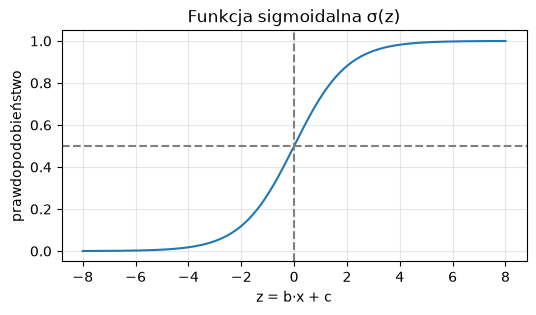

In [54]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 3))
plt.plot(z, 1 / (1 + np.exp(-z))) # wzór funkcji sigmoidalnej
plt.axhline(0.5, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")
plt.title("Funkcja sigmoidalna σ(z)")
plt.xlabel("z = b·x + c")
plt.ylabel("prawdopodobieństwo")
plt.grid(True, alpha=0.3)
plt.show()

### Model na podstawie jednej cechy

Zaczynamy od jednej cechy: `study_hours_per_day` tak jak robiliśmy w regresji liniowej.

> **Uwaga techniczna:** cechy `X` muszą być **dwuwymiarowe** (tabela), stąd podwójny nawias `df[["..."]]`.
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [55]:
from sklearn.linear_model import LogisticRegression

X1 = df[["study_hours_per_day"]]   
# y  = df["zdal"]                  

# ZADANIE 2 - utwórz model LogisticRegression(max_iter=5000) i naucz go na (X1, y)

# print("Nauczono model.")
# print("Współczynnik b:", model.coef_[0][0].round(3), "| wyraz wolny c:", model.intercept_[0].round(3))

### Krzywa prawdopodobieństwa i granica decyzyjna

Zamiast prostej (jak w regresji) dostajemy **krzywą** prawdopodobieństwa. Miejsce, w którym przecina ona poziom 0.5, to **granica decyzyjna** - poniżej model typuje "nie zdał", powyżej "zdał". Formalnie granica to `x`, dla którego `b·x + c = 0`, czyli:

$$x_{\text{granica}} = -\frac{c}{b}$$


In [56]:
# xs = np.linspace(df["study_hours_per_day"].min(), df["study_hours_per_day"].max(), 200).reshape(-1, 1)
# ps = model.predict_proba(xs)[:, 1]     # prawdopodobieństwo klasy 1
# # granica = DOKOŃCZ WZÓR NA PODSTAWIE WSPÓŁCZYNNIKÓW B I C (model.coef_, model.intercept_) 

# plt.figure(figsize=(7, 4))
# plt.scatter(df["study_hours_per_day"], df["zdal"], s=8, alpha=0.3, label="studenci")
# plt.plot(xs, ps, color="red", lw=2, label="P(zdał)")
# plt.axhline(0.5, color="gray", ls="--")
# plt.axvline(granica, color="green", ls="--", label=f"granica ≈ {granica:.1f} h")
# plt.xlabel("godziny nauki dziennie")
# plt.ylabel("prawdopodobieństwo zdania")
# plt.legend(); plt.grid(True, alpha=0.3)
# plt.show()

# print(f"Powyżej ok. {granica:.1f} h nauki model typuje 'zdał'.")

### Jak ocenić klasyfikator? - nowe metryki

W regresji mierzyliśmy błąd w jednostkach celu (MAE, RMSE). W klasyfikacji liczymy **trafienia i pomyłki**. Podstawą jest **macierz pomyłek** - zestawienie, co model przewidział, a jak było naprawdę:

|                    | przewidziano 0 | przewidziano 1 |
|--------------------|:--------------:|:--------------:|
| **naprawdę 0**     | TN (trafienie) | FP (fałszywy alarm) |
| **naprawdę 1**     | FN (przeoczenie) | TP (trafienie) |

Z niej liczymy cztery najważniejsze metryki:

$$\text{accuracy} = \frac{TP+TN}{\text{wszystkie}} \qquad \text{precision} = \frac{TP}{TP+FP}$$
$$\text{recall} = \frac{TP}{TP+FN} \qquad F_1 = \frac{2\cdot \text{precision}\cdot \text{recall}}{\text{precision}+\text{recall}}$$

Po polsku: 
- **accuracy** = odsetek wszystkich trafień; 
- **precision** = spośród oznaczonych jako „zdał", ilu naprawdę zdało; 
- **recall** = spośród prawdziwych „zdał", ilu wychwyciliśmy; 
- **F1** = kompromis precyzji i czułości.

Żadna z tych metryk nie jest „najlepsza" - każda pokazuje coś innego i każda ma sytuacje, w których zwodzi:

- **accuracy** - zawodzi przy **niezrównoważonych klasach**. Gdyby 95% studentów zdawało, model mówiący zawsze zdał miałby 95% accuracy i byłby bezużyteczny.
- **precision** - można ją sztucznie zawyżyć, oznaczając jako zdał tylko przypadki **pewne na 100%**: precyzja będzie wysoka, ale model przegapi większość zdających.
- **recall** - łatwo ją oszukać w drugą stronę: model przewidujący zdał **dla wszystkich** osiąga recall = 1.0, ale ma fatalną precyzję.
- **F1** - łączy precision i recall, ale traktuje je **równo wagowo**, co nie zawsze pasuje do problemu (czasem czułość jest dużo ważniejsza niż precyzja - albo odwrotnie). F1 **w ogóle nie patrzy na TN**, więc tam, gdzie trafne odrzucenia są istotne, nie mówi całej prawdy. Jest niska, gdy **którakolwiek** ze składowych jest niska.

> **Którą metrykę wybrać?** Zależy od tego, **który błąd jest gorszy**. Przy wykrywaniu spamu gorszy jest fałszywy alarm (FP) - wpadający do kosza ważny e-mail - więc liczy się **precyzja**. Przy wykrywaniu choroby gorsze jest przeoczenie (FN) - chory pacjent uznany za zdrowego - więc liczy się **czułość (recall)**. Dlatego zwykle patrzymy na **kilka metryk naraz**, a nie na jedną.

In [57]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
y_pred = model.predict(X1)

# ZADANIE 3 - wypisz accuracy, precision, recall i F1 
print("accuracy: ")
print("precision:")
print("recall:   ")
print("F1:       ")

print("\nMacierz pomyłek [[TN, FP], [FN, TP]]:")

accuracy: 
precision:
recall:   
F1:       

Macierz pomyłek [[TN, FP], [FN, TP]]:


### Wiele cech naraz

Tak jak w regresji dokładaliśmy kolumny, tu też damy modelowi więcej informacji: sen, obecność, media itd. Każda cecha dostaje swój współczynnik:

$$\hat{p} = \sigma(b_1 x_1 + b_2 x_2 + \dots + b_n x_n + c)$$

**Interpretacja współczynnika.** W regresji logistycznej `b_i` opisuje wpływ cechy na **logarytm szans** (log-odds):

$$\ln\!\left(\frac{p}{1-p}\right) = b_1 x_1 + \dots + b_n x_n + c$$

Wygodniej patrzeć na **iloraz szans** $e^{b_i}$: 
- wartość **> 1** oznacza, że cecha **zwiększa** szansę na zdanie, 
- wartość **< 1** - że ją **zmniejsza**. 

In [58]:
kandydaci = ["study_hours_per_day", "sleep_hours", "social_media_hours",
             "netflix_hours", "attendance_percentage", "mental_health_rating",
             "exercise_frequency"]
cechy = [k for k in kandydaci if k in df.columns]

# dane = df[cechy + ["zdal"]].dropna()
# X_multi = dane[cechy]
# y_multi = dane["zdal"]

# ZADANIE 4 - utwórz LogisticRegression

# print("Iloraz szans exp(b) dla każdej cechy:")
# for nazwa, w in zip(cechy, model_multi.coef_[0]):
#     kier = "zwiększa" if w > 0 else "zmniejsza"
#     print(f"  {nazwa:<24} exp(b)={np.exp(w):.3f}  ({kier} szansę)")

## 3. Przygotowanie do innych metod: skalowanie i podział train/test

Kolejne metody oparte są na **odległościach** między punktami. 
Problem: jeśli jedna cecha ma zakres 0–100 (obecność w %), a inna 0–10 (godziny), to ta pierwsza zdominuje odległość samą skalą. Dlatego cechy **standaryzujemy** - każdą przeskalowujemy tak, by miała średnią 0 i odchylenie 1:

$$x' = \frac{x - \mu}{\sigma}$$

gdzie `μ` to średnia, a `σ` odchylenie standardowe cechy.

**Ważne: skaler ucz tylko na danych treningowych.**

Standaryzacja potrzebuje dwóch liczb dla każdej cechy - średniej i odchylenia. Pytanie brzmi: z których danych je policzyć?

Zasada: liczymy je **wyłącznie ze zbioru treningowego** (`fit` na treningu), a potem **tymi samymi liczbami** przekształcamy oba zbiory — i treningowy, i testowy (`transform` na obu).

Dlaczego? Zbiór testowy udaje "nowe dane, których model jeszcze nie widział" - ma sprawdzić, jak model poradzi sobie w przyszłości. Gdybyśmy przy liczeniu średniej i odchylenia zajrzeli też do testu, to informacja o nim "przeciekłaby" do przygotowania danych. Model pośrednio poznałby test jeszcze przed oceną, a wynik wyszedłby **zawyżony** - nie wiedzielibyśmy, jak naprawdę zadziała na świeżych danych.

To trochę jak z egzaminem: przygotowujesz się na materiale z zajęć (trening), a arkusz egzaminacyjny (test) widzisz dopiero na egzaminie. Gdybyś podejrzał go wcześniej, świetny wynik nic by nie mówił o Twojej wiedzy.

W praktyce ten problem nazywa się **wyciekiem danych** (*data leakage*) i łatwo go popełnić - dlatego pilnujemy, żeby `fit` dotykał tylko treningu.

> Podział na trening i test znasz już z regresji. Drzewa i lasy skalowania nie potrzebują, ale też nie jest przeciwskazane skalowanie.

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# ZADANIE 5 - podziel dane na trening/test

# Skalowanie
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
print("Trening:", X_train_s.shape, "| Test:", X_test_s.shape)

Trening: (800, 7) | Test: (200, 7)


## 4. Więcej metod klasyfikacji

Regresja logistyczna to jedna z wielu metod. Poznamy cztery kolejne. Zauważ, że w kodzie **schemat jest zawsze ten sam**:

`utwórz model → .fit(trening) → .predict(test) → oceń`

Różni się tylko "filozofia" działania każdej metody.

### Metoda 1: k najbliższych sąsiadów (k-NN)

https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

**Intuicja:** właściwie się nie uczy. W fazie treningu jedynie zapamiętuje wszystkie przykłady. Cała praca dzieje się przy predykcji: dla nowego punktu liczymy jego odległość do każdego punktu treningowego, wybieramy k najbliższych i bierzemy wśród nich głos większości. "Powiedz mi, kim są twoi sąsiedzi, a powiem ci, kim jesteś."

Odległość między punktami liczymy zwykle wzorem **euklidesowym** (twierdzenie Pitagorasa w wielu wymiarach):

$$d(\mathbf{x}, \mathbf{q}) = \sqrt{\sum_{i} (x_i - q_i)^2}$$

**Parametry:** `n_neighbors` (ile sąsiadów głosuje - małe `k` = elastyczne, ale wrażliwe na szum; duże `k` = gładsze), `weights` (czy bliżsi sąsiedzi ważą więcej).

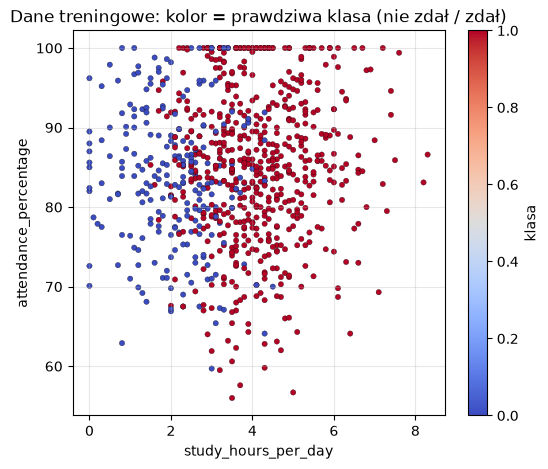

In [60]:
# Intuicja k-NN: punkty leżące blisko siebie zwykle należą do tej samej klasy.
c1, c2 = "study_hours_per_day", "attendance_percentage"   # można podmienić na inne cechy

plt.figure(figsize=(6, 5))
plt.scatter(X_train[c1], X_train[c2], c=y_train, cmap="coolwarm",
            s=15, edgecolors="k", linewidths=0.2)
plt.xlabel(c1); plt.ylabel(c2)
plt.title("Dane treningowe: kolor = prawdziwa klasa (nie zdał / zdał)")
plt.colorbar(label="klasa"); plt.grid(True, alpha=0.3)
plt.show()

In [61]:
from sklearn.neighbors import KNeighborsClassifier
# ZADANIE 6 - utwórz KNeighborsClassifier(n_neighbors=5), naucz na (X_train_s, y_train),
#   dokonaj predykcji dla X_test_s i wypisz accuracy względem y_test
# knn = 
print("k-NN accuracy:")

k-NN accuracy:


### Metoda 2: drzewo decyzyjne

https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

**Intuicja:** Drzewo dzieli dane serią pytań tak/nie o pojedyncze cechy. Uczenie polega na rekurencyjnym podziale: w każdym węźle algorytm sprawdza różne cechy i progi, i wybiera ten podział, który najlepiej rozdziela klasy. „Najlepiej" mierzy się spadkiem nieczystości — najczęściej wskaźnikiem Giniego: $$gini=1−\sum_i p_i^2 $$, gdzie $p_i$ to udział klasy w węźle. Gini = 0 oznacza węzeł idealnie czysty (jedna klasa), a przy dwóch klasach maksimum 0,5 (pół na pół). Drzewo zachłannie wybiera podział dający największy ważony spadek Giniego, po czym powtarza to w każdej gałęzi.

**Parametry:** `max_depth` (maksymalna głębokość - za duża grozi **przeuczeniem**, czyli uczeniem się szumu), `min_samples_leaf`. Atrybut `feature_importances_` mówi, które cechy najbardziej ważą.

In [62]:
from sklearn.tree import DecisionTreeClassifier
# ZADANIE 7 - utwórz DecisionTreeClassifier i naucz na treningu
# drzewo =

# print("Drzewo accuracy:", round(accuracy_score(y_test, drzewo.predict(X_test_s)), 3))
# print("\nWażność cech:")
# for nazwa, w in sorted(zip(cechy, drzewo.feature_importances_), key=lambda t: -t[1]):
#     print(f"  {nazwa:<24} {w:.3f}")


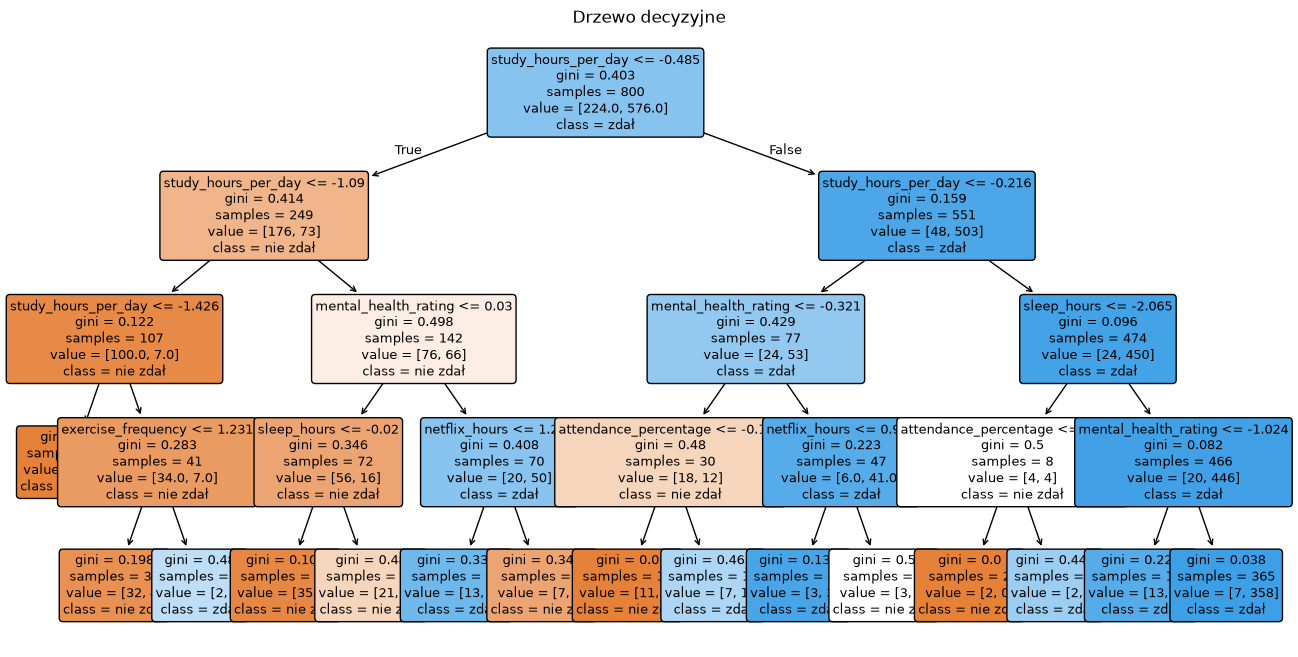

In [63]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))
plot_tree(drzewo,
          feature_names=cechy,                    # nazwy cech na węzłach
          class_names=["nie zdał", "zdał"],       # nazwy klas w liściach
          filled=True,                            # kolor = klasa większościowa
          rounded=True,
          fontsize=9)
plt.title("Drzewo decyzyjne")
plt.show()

### Metoda 3: las losowy (Random Forest)

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

**Intuicja:** zamiast jednego drzewa budujemy **setki**, każde na trochę innym losowym podzbiorze danych i cech - a potem **głosują**. Pojedyncze drzewo łatwo się myli; "mądrość tłumu" drzew daje stabilniejszy i zwykle dokładniejszy wynik.

**Parametry:** `n_estimators` (liczba drzew - więcej = stabilniej, wolniej), `max_depth`.

In [64]:
from sklearn.ensemble import RandomForestClassifier
# ZADANIE 8 - utwórz RandomForestClassifier
# las = 

# print("Las losowy accuracy:", round(accuracy_score(y_test, las.predict(X_test_s)), 3))

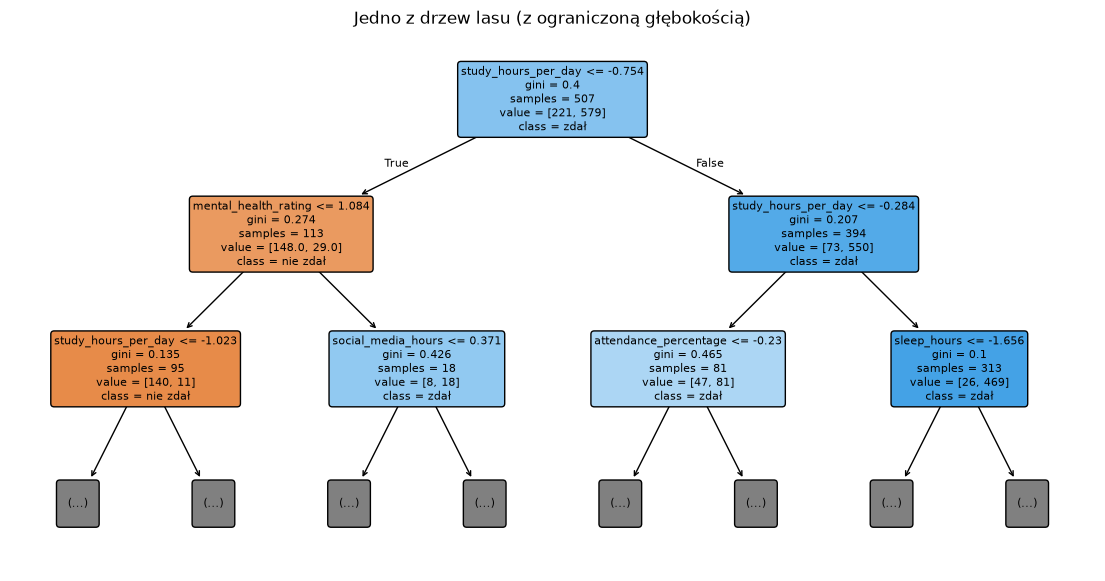

In [65]:
plt.figure(figsize=(14, 7))
plot_tree(las.estimators_[5],                 # wybierz numer drzewa
          feature_names=cechy, class_names=["nie zdał", "zdał"],
          filled=True, rounded=True, max_depth=2, fontsize=8)
plt.title("Jedno z drzew lasu (z ograniczoną głębokością)")
plt.show()

### Metoda 4: SVM (maszyna wektorów nośnych)

https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

**Intuicja:** SVM szuka granicy (hiperpłaszczyzny) rozdzielającej klasy, ale nie byle jakiej - takiej z najszerszym marginesem, czyli największym odstępem od najbliższych punktów obu klas. Intuicja: im szerszy "pas bezpieczeństwa" wokół granicy, tym pewniej model uogólnia się na nowe dane. Granicę wyznaczają wyłącznie punkty leżące na marginesie - to wektory nośne (stąd nazwa). Punkty daleko od granicy nie mają na nią wpływu - można je usunąć i granica się nie zmieni.

Ponieważ dane rzadko dają się rozdzielić idealnie, stosuje się miękki margines: parametr `C` reguluje, jak bardzo tolerujemy punkty naruszające margines. Duże C = mało tolerancji (wąski margines, ryzyko przeuczenia), małe C = szerszy margines i ogólniejszy model.

**Parametry:** `C` (kompromis: duże `C` = mniejsza tolerancja na błędy), `kernel`, `gamma`. 

In [66]:
from sklearn.svm import SVC
# ZADANIE 9 - utwórz SVC(), naucz na treningu i wypisz accuracy na teście
# svm = 

# print("SVM accuracy:", round(accuracy_score(y_test, svm.predict(X_test_s)), 3))

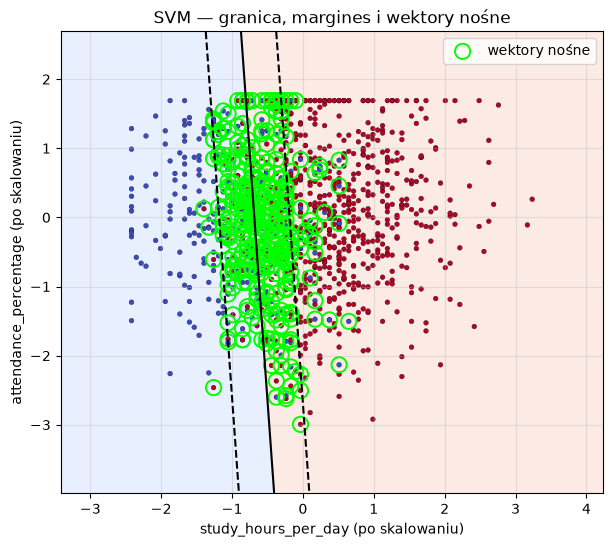

In [67]:
# Wybieramy 2 cechy (żeby dało się narysować) i standaryzujemy je
c1, c2 = "study_hours_per_day", "attendance_percentage"
X2 = StandardScaler().fit_transform(dane[[c1, c2]].to_numpy())
y2 = dane["zdal"].to_numpy()

# Uczymy SVM na tych 2 cechach
svm_viz = SVC(kernel="linear", C=1.0).fit(X2, y2)   # spróbuj też kernel="rbf"

# Siatka punktów pokrywająca wykres
xx, yy = np.meshgrid(np.linspace(X2[:, 0].min()-1, X2[:, 0].max()+1, 300),
                     np.linspace(X2[:, 1].min()-1, X2[:, 1].max()+1, 300))
Z = svm_viz.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7, 6))
# kolorowe obszary decyzji (dwie klasy)
plt.contourf(xx, yy, Z > 0, alpha=0.2, cmap="coolwarm")
# granica decyzyjna (linia ciągła) + margines (linie przerywane)
plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
# dane, kolor = klasa
plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="coolwarm", s=12, edgecolors="k", linewidths=0.2)
# wektory nośne - punkty na marginesie, które wyznaczają granicę
plt.scatter(svm_viz.support_vectors_[:, 0], svm_viz.support_vectors_[:, 1],
            s=120, facecolors="none", edgecolors="lime", linewidths=1.4,
            label="wektory nośne")
plt.xlabel(c1 + " (po skalowaniu)")
plt.ylabel(c2 + " (po skalowaniu)")
plt.title("SVM — granica, margines i wektory nośne")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Porównanie metod w tabeli

Zbierzmy metody w słowniku i porównajmy je **jedną pętlą** - dla każdej liczymy komplet metryk. To wygodny wzorzec: dopisanie nowej metody to jedna linijka w słowniku.

In [68]:
modele = {
    "k-NN":          KNeighborsClassifier(n_neighbors=5),
    "Drzewo":        DecisionTreeClassifier(max_depth=4, random_state=42),
    "Las losowy":    RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM ":     SVC(C=1.0),
    "Regresja log.": LogisticRegression(max_iter=5000),
}

wyniki = []
for nazwa, m in modele.items():
    m.fit(X_train_s, y_train)
    yp = m.predict(X_test_s)
    wyniki.append({
        "model": nazwa,
        "accuracy":  accuracy_score(y_test, yp),
        "precision": precision_score(y_test, yp, zero_division=0),
        "recall":    recall_score(y_test, yp, zero_division=0),
        "F1":        f1_score(y_test, yp, zero_division=0),
    })

print(pd.DataFrame(wyniki).set_index("model").round(3))

               accuracy  precision  recall     F1
model                                            
k-NN              0.860      0.867   0.951  0.907
Drzewo            0.865      0.909   0.903  0.906
Las losowy        0.915      0.926   0.958  0.942
SVM               0.900      0.925   0.938  0.931
Regresja log.     0.920      0.938   0.951  0.945


**Jak to czytać?** Na prostych, dobrze rozdzielonych danych metody często dają **zbliżone** wyniki - nie ma jednej "najlepszej" zawsze. Wybór to kompromis: drzewo i regresja są łatwe do wyjaśnienia, las i SVM bywają dokładniejsze, ale trudniejsze do interpretacji. Skalowanie jest kluczowe dla k-NN i SVM, obojętne dla drzew.

## Podsumowanie

- **Klasyfikacja** przewiduje **kategorię**, a nie liczbę - to główna różnica względem regresji.
- **Regresja logistyczna** bierze prostą `b·x + c` i przepuszcza ją przez **sigmoidę**, dając **prawdopodobieństwo**; próg 0.5 zamienia je w decyzję.
- **Metryki klasyfikacji** (accuracy, precision, recall, F1, macierz pomyłek) mówią nie tylko *ile* trafień, ale i *gdzie* model się myli - a sama accuracy potrafi zwodzić.
- Metody różnią się "filozofią" (sąsiedzi, pytania, głosowanie drzew, margines), ale w kodzie używamy ich **tak samo**: `utwórz → fit → predict → oceń`.
- **Skalowanie** cech jest konieczne dla metod opartych na odległości (k-NN, SVM).